In [41]:
# ============================================================
# CELL 2 — LOAD PROJECT FROM GITHUB
# ============================================================

import os

REPO_DIR = "/content/TA"

if not os.path.exists(REPO_DIR):
    !git clone https://github.com/shefiramarizcha62-sudo/TA.git "$REPO_DIR"

print("Repository:", REPO_DIR)

!find "$REPO_DIR/dataset" -maxdepth 2 -type f | sort

Repository: /content/TA
/content/TA/dataset/dataset_minimal_C0-C4.csv
/content/TA/dataset/dataset_preprocessed_C0-C4_revised.csv
/content/TA/dataset/splits/test_split.csv
/content/TA/dataset/splits/train_split.csv
/content/TA/dataset/splits/validation_split.csv


In [42]:
# ============================================================
# CELL 3 — LOAD EXISTING SPLITS
# ============================================================

SPLIT_DIR = "/content/TA/dataset/splits"

TRAIN_PATH = os.path.join(
    SPLIT_DIR,
    "train_split.csv"
)

VAL_PATH = os.path.join(
    SPLIT_DIR,
    "validation_split.csv"
)

TEST_PATH = os.path.join(
    SPLIT_DIR,
    "test_split.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

display(train_df.head())

Train      : (3052, 3)
Validation : (381, 3)
Test       : (382, 3)


,Komentar_preprocessed,Kode Label,label
0,wah sudah parah kesal ini roman2 nya bang fery...,C0,0
1,rakyat khawatir ternyata prabowo sejenis dia.😅,C4,4
2,ah pak pigai sudah banyak minum susu ini 😂 dan...,C3,3
3,terus apa hubungan kewaspadaan dengan keturuna...,C0,0
4,yang bikin uu membolehkan siapa mirip pendukun...,C1,1


In [43]:
# ============================================================
# CELL 2 — VALIDATE DATASET SPLITS
# ============================================================

# ------------------------------------------------------------
# DEFINE TEXT AND LABEL COLUMNS
# ------------------------------------------------------------

TEXT_COL = "Komentar_preprocessed"
LABEL_COL = "Kode Label"

EXPECTED_LABELS = ["C0", "C1", "C2", "C3", "C4"]

# ------------------------------------------------------------
# CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

for split_name, dataframe in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():

    missing_cols = [
        col for col in [TEXT_COL, LABEL_COL]
        if col not in dataframe.columns
    ]

    if missing_cols:
        raise ValueError(
            f"{split_name} tidak memiliki kolom: {missing_cols}"
        )

# ------------------------------------------------------------
# CHECK MISSING VALUES
# ------------------------------------------------------------

for split_name, dataframe in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():

    print(f"\n{split_name}")
    print("Missing text :", dataframe[TEXT_COL].isna().sum())
    print("Missing label:", dataframe[LABEL_COL].isna().sum())

    if dataframe[[TEXT_COL, LABEL_COL]].isna().any().any():
        raise ValueError(
            f"Ditemukan missing value pada {split_name}."
        )

# ------------------------------------------------------------
# NORMALIZE LABEL FORMAT
# ------------------------------------------------------------

for dataframe in [train_df, val_df, test_df]:
    dataframe[LABEL_COL] = (
        dataframe[LABEL_COL]
        .astype(str)
        .str.strip()
        .str.upper()
    )

# ------------------------------------------------------------
# CHECK LABEL CATEGORIES
# ------------------------------------------------------------

for split_name, dataframe in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():

    labels_found = sorted(dataframe[LABEL_COL].unique())

    print(f"\n{split_name} label distribution:")
    print(dataframe[LABEL_COL].value_counts().sort_index())

    if set(labels_found) != set(EXPECTED_LABELS):
        raise ValueError(
            f"Label pada {split_name} tidak sesuai. "
            f"Ditemukan: {labels_found}"
        )

# ------------------------------------------------------------
# CHECK SPLIT SIZE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SPLIT SIZE VALIDATION")
print("=" * 60)

print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))
print("Total      :", len(train_df) + len(val_df) + len(test_df))

# ------------------------------------------------------------
# CHECK OVERLAPPING TEXT
# ------------------------------------------------------------

train_texts = set(train_df[TEXT_COL].astype(str))
val_texts = set(val_df[TEXT_COL].astype(str))
test_texts = set(test_df[TEXT_COL].astype(str))

print("\n" + "=" * 60)
print("OVERLAP CHECK")
print("=" * 60)

print("Train ∩ Validation :", len(train_texts & val_texts))
print("Train ∩ Test       :", len(train_texts & test_texts))
print("Validation ∩ Test  :", len(val_texts & test_texts))

print("\nDataset validation selesai.")


Train
Missing text : 0
Missing label: 0

Validation
Missing text : 0
Missing label: 0

Test
Missing text : 0
Missing label: 0

Train label distribution:
Kode Label
C0    610
C1    611
C2    610
C3    610
C4    611
Name: count, dtype: int64

Validation label distribution:
Kode Label
C0    76
C1    76
C2    77
C3    76
C4    76
Name: count, dtype: int64

Test label distribution:
Kode Label
C0    77
C1    76
C2    76
C3    77
C4    76
Name: count, dtype: int64

SPLIT SIZE VALIDATION
Train      : 3052
Validation : 381
Test       : 382
Total      : 3815

OVERLAP CHECK
Train ∩ Validation : 0
Train ∩ Test       : 1
Validation ∩ Test  : 0

Dataset validation selesai.


In [44]:
# ============================================================
# CELL 3 — CONFIGURATION & TOKENIZER
# ============================================================

import torch
from transformers import AutoTokenizer

MODEL_NAME = "indobenchmark/indobert-large-p2"

MAX_LENGTH = 256
SLICE_LENGTH = 128

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

NUM_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2

SEED = 42

print("=" * 70)
print("SLICING EXPERIMENT CONFIGURATION")
print("=" * 70)

print("Model          :", MODEL_NAME)
print("MAX_LENGTH     :", MAX_LENGTH)
print("SLICE_LENGTH   :", SLICE_LENGTH)
print("Learning Rate  :", LEARNING_RATE)
print("Weight Decay   :", WEIGHT_DECAY)
print("Max Epochs     :", NUM_EPOCHS)
print("Early Stopping :", EARLY_STOPPING_PATIENCE)
print("Seed           :", SEED)
print("Device         :", "CUDA" if torch.cuda.is_available() else "CPU")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("\nTokenizer berhasil dimuat.")
print("Tokenizer:", tokenizer.__class__.__name__)

SLICING EXPERIMENT CONFIGURATION
Model          : indobenchmark/indobert-large-p2
MAX_LENGTH     : 256
SLICE_LENGTH   : 128
Learning Rate  : 2e-05
Weight Decay   : 0.01
Max Epochs     : 10
Early Stopping : 2
Seed           : 42
Device         : CUDA

Tokenizer berhasil dimuat.
Tokenizer: BertTokenizer


In [45]:
# ============================================================
# CELL 4 — TOKEN SLICING FUNCTION
# ============================================================

def slice_text(text, tokenizer, slice_length=128):

    text = str(text).strip()

    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False
    )

    if len(token_ids) == 0:
        return [text]

    slices = []

    for start in range(0, len(token_ids), slice_length):

        chunk_ids = token_ids[start:start + slice_length]

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=True
        ).strip()

        if chunk_text:
            slices.append(chunk_text)

    return slices if slices else [text]


# ------------------------------------------------------------
# TEST SLICING FUNCTION
# ------------------------------------------------------------

sample_text = train_df.iloc[0][TEXT_COL]

sample_slices = slice_text(
    sample_text,
    tokenizer,
    SLICE_LENGTH
)

print("Original text:")
print(sample_text)

print("\nJumlah slice:", len(sample_slices))

for i, chunk in enumerate(sample_slices):
    print(f"\nSlice {i + 1}:")
    print(chunk)

Original text:
wah sudah parah kesal ini roman2 nya bang fery sampai gemeteran cuy bicara nya

Jumlah slice: 1

Slice 1:
wah sudah parah kesal ini roman2 nya bang fery sampai gemeteran cuy bicara nya


In [46]:
# ============================================================
# CELL 5 — APPLY SLICING TO ALL SPLITS
# ============================================================

def create_sliced_dataset(dataframe, split_name):

    rows = []

    for original_index, row in dataframe.reset_index(drop=True).iterrows():

        text = row[TEXT_COL]
        label = row[LABEL_COL]

        slices = slice_text(
            text,
            tokenizer,
            SLICE_LENGTH
        )

        for slice_id, chunk in enumerate(slices):

            rows.append({
                "original_index": original_index,
                "slice_id": slice_id,
                "text": chunk,
                "label": label,
                "split": split_name
            })

    return pd.DataFrame(rows)


train_sliced = create_sliced_dataset(train_df, "train")
val_sliced = create_sliced_dataset(val_df, "validation")
test_sliced = create_sliced_dataset(test_df, "test")

print("=" * 70)
print("SLICING COMPLETED")
print("=" * 70)

print("Train original     :", len(train_df))
print("Train after slicing:", len(train_sliced))

print("\nValidation original     :", len(val_df))
print("Validation after slicing:", len(val_sliced))

print("\nTest original     :", len(test_df))
print("Test after slicing:", len(test_sliced))

display(train_sliced.head(10))

SLICING COMPLETED
Train original     : 3052
Train after slicing: 3168

Validation original     : 381
Validation after slicing: 406

Test original     : 382
Test after slicing: 405


,original_index,slice_id,text,label,split
0,0,0,wah sudah parah kesal ini roman2 nya bang fery...,C0,train
1,1,0,rakyat khawatir ternyata prabowo sejenis dia.,C4,train
2,2,0,ah pak pigai sudah banyak minum susu ini dan m...,C3,train
3,3,0,terus apa hubungan kewaspadaan dengan keturuna...,C0,train
4,4,0,yang bikin uu membolehkan siapa mirip pendukun...,C1,train
5,5,0,apa guna uud kalau hukuman mati sama perampasa...,C2,train
6,6,0,gog gog gog odgj lagi gong gong,C4,train
7,7,0,"mantap grace natalie, sukses terus untuk psi.",C0,train
8,8,0,apa mendikbud tidak ikut bersalah dengan membi...,C1,train
9,9,0,kalau sampai 3 priode rakyat tambah pecah.,C1,train


In [47]:
# ============================================================
# CELL 6 — LABEL DISTRIBUTION AFTER SLICING
# ============================================================

print("=" * 70)
print("LABEL DISTRIBUTION AFTER SLICING")
print("=" * 70)

for split_name, dataframe in {
    "Train": train_sliced,
    "Validation": val_sliced,
    "Test": test_sliced
}.items():

    print(f"\n{split_name}")
    print(dataframe["label"].value_counts().sort_index())

    print(
        "Jumlah komentar asli:",
        dataframe["original_index"].nunique()
    )

    print(
        "Jumlah slice:",
        len(dataframe)
    )

LABEL DISTRIBUTION AFTER SLICING

Train
label
C0    615
C1    633
C2    632
C3    677
C4    611
Name: count, dtype: int64
Jumlah komentar asli: 3052
Jumlah slice: 3168

Validation
label
C0    80
C1    78
C2    80
C3    91
C4    77
Name: count, dtype: int64
Jumlah komentar asli: 381
Jumlah slice: 406

Test
label
C0    79
C1    85
C2    77
C3    87
C4    77
Name: count, dtype: int64
Jumlah komentar asli: 382
Jumlah slice: 405


In [48]:
# ============================================================
# CELL 7 — LABEL ENCODING & TOKENIZATION
# ============================================================

label2id = {
    "C0": 0,
    "C1": 1,
    "C2": 2,
    "C3": 3,
    "C4": 4
}

id2label = {
    value: key for key, value in label2id.items()
}


def tokenize_dataset(dataframe):

    encodings = tokenizer(
        dataframe["text"].tolist(),
        padding=False,
        truncation=True,
        max_length=MAX_LENGTH
    )

    encodings["labels"] = [
        label2id[label]
        for label in dataframe["label"]
    ]

    return encodings


train_encodings = tokenize_dataset(train_sliced)
val_encodings = tokenize_dataset(val_sliced)
test_encodings = tokenize_dataset(test_sliced)

print("Tokenization completed.")

print("Train samples:", len(train_encodings["labels"]))
print("Validation samples:", len(val_encodings["labels"]))
print("Test samples:", len(test_encodings["labels"]))

Tokenization completed.
Train samples: 3168
Validation samples: 406
Test samples: 405


In [49]:
# ============================================================
# CELL 8 — CREATE HUGGING FACE DATASET
# ============================================================

from datasets import Dataset

train_dataset = Dataset.from_dict(train_encodings)
val_dataset = Dataset.from_dict(val_encodings)
test_dataset = Dataset.from_dict(test_encodings)

print(train_dataset)
print(val_dataset)
print(test_dataset)

Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 3168
})
Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 406
})
Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 405
})


In [50]:
# ============================================================
# CELL 9 — DATA COLLATOR
# ============================================================

from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True
)

print("Dynamic padding enabled.")

Dynamic padding enabled.


In [51]:
# ============================================================
# CELL 10 — LOAD INDOBERT LARGE P2
# ============================================================

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5,
    id2label=id2label,
    label2id=label2id
)

print("Model:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-large-p2
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: indobenchmark/indobert-large-p2
Number of labels: 5


In [52]:
# ============================================================
# CELL 11 — EVALUATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": f1
    }

In [53]:
# ============================================================
# CELL 12 — CLASS WEIGHTS
# ============================================================

from sklearn.utils.class_weight import compute_class_weight

train_label_ids = np.array([
    label2id[label]
    for label in train_sliced["label"]
])

classes = np.array([0, 1, 2, 3, 4])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_label_ids
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("Class weights:")

for class_id, weight in enumerate(class_weights):
    print(f"{id2label[class_id]}: {weight.item():.4f}")

Class weights:
C0: 1.0302
C1: 1.0009
C2: 1.0025
C3: 0.9359
C4: 1.0370


In [54]:
# ============================================================
# CELL 13 — WEIGHTED TRAINER
# ============================================================

import torch.nn as nn

from transformers import Trainer


class WeightedTrainer(Trainer):

    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)

        self.class_weights = class_weights

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        weights = self.class_weights.to(logits.device)

        loss_fct = nn.CrossEntropyLoss(
            weight=weights
        )

        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss

In [55]:
# =========================================================
# Experiment Configuration
# =========================================================

MODEL_NAME = "indobenchmark/indobert-large-p2"

MAX_LENGTH = 256
SLICE_LENGTH = 128

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

NUM_EPOCHS = 10
BATCH_SIZE = 4

EARLY_STOPPING_PATIENCE = 2
SEED = 42

In [56]:
# ============================================================
# CHECK TOKENIZED DATASET — SLICING
# ============================================================

tokenized_train = train_dataset
tokenized_val = val_dataset
tokenized_test = test_dataset

print("Dataset siap digunakan untuk training.")

print(f"Train      : {len(tokenized_train)}")
print(f"Validation : {len(tokenized_val)}")
print(f"Test       : {len(tokenized_test)}")

print("\nKolom dataset:")
print(tokenized_train.column_names)

print("\nContoh data:")
print(tokenized_train[0])

Dataset siap digunakan untuk training.
Train      : 3168
Validation : 406
Test       : 405

Kolom dataset:
['input_ids', 'token_type_ids', 'attention_mask', 'labels']

Contoh data:
{'input_ids': [2, 2282, 259, 4762, 10531, 92, 18449, 30378, 1107, 1719, 6028, 30371, 493, 5536, 2194, 5, 4250, 30371, 4007, 1107, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': 0}


In [57]:
# ============================================================
# CELL 15 — CREATE TRAINER
# ============================================================

from transformers import EarlyStoppingCallback

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,

    data_collator=data_collator,

    processing_class=tokenizer,

    compute_metrics=compute_metrics,

    class_weights=class_weights,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=EARLY_STOPPING_PATIENCE
        )
    ]
)

print("WeightedTrainer berhasil dibuat.")

WeightedTrainer berhasil dibuat.


In [58]:
# ============================================================
# CELL 16 — TRAINING SLICING EXPERIMENT
# ============================================================

print("=" * 70)
print("START TRAINING — SLICING EXPERIMENT")
print("=" * 70)

train_result = trainer.train()

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation metric:", trainer.state.best_metric)

print("\nTraining metrics:")
print(train_result.metrics)

START TRAINING — SLICING EXPERIMENT


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,1.435256,1.286343,0.445813,0.477503,0.450332,0.422232
2,1.008006,1.300828,0.507389,0.517123,0.502884,0.488584
3,0.517414,2.218809,0.509852,0.528294,0.511323,0.508772
4,0.201752,2.764229,0.519704,0.540063,0.519303,0.522961
5,0.093403,3.644369,0.485222,0.501818,0.489557,0.485098
6,0.064081,3.676226,0.495074,0.499678,0.495444,0.494098


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TRAINING COMPLETED
Best checkpoint: ./results_slicing/checkpoint-3168
Best validation metric: 0.5229607159020474

Training metrics:
{'train_runtime': 1302.7722, 'train_samples_per_second': 24.317, 'train_steps_per_second': 6.079, 'total_flos': 2276789644466112.0, 'train_loss': 0.5533186955885454, 'epoch': 6.0}


In [59]:
# ============================================================
# CELL 17 — VALIDATION EVALUATION (SLICE LEVEL)
# ============================================================

val_metrics = trainer.evaluate(
    eval_dataset=val_dataset
)

print("=" * 70)
print("VALIDATION METRICS — SLICE LEVEL")
print("=" * 70)

for metric, value in val_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,Macro F1
0.064081,2.764229,6,0.519704,0.540063,0.519303,0.522961


VALIDATION METRICS — SLICE LEVEL
eval_loss: 2.7642
eval_accuracy: 0.5197
eval_precision: 0.5401
eval_recall: 0.5193
eval_macro_f1: 0.5230


In [60]:
# ============================================================
# CELL 18 — AGGREGATE SLICE PREDICTIONS
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

def aggregate_predictions(
    logits,
    sliced_dataframe,
    original_dataframe
):

    temp = sliced_dataframe[
        ["original_index", "slice_id", "label"]
    ].copy()

    temp["true_id"] = temp["label"].map(label2id).astype(int)

    temp["logits"] = list(logits)

    results = []

    for original_index, group in temp.groupby(
        "original_index",
        sort=True
    ):

        true_labels = group["true_id"].unique()

        if len(true_labels) != 1:
            raise ValueError(
                f"Label tidak konsisten pada komentar {original_index}"
            )

        mean_logits = np.mean(
            np.stack(group["logits"].values),
            axis=0
        )

        predicted_id = int(np.argmax(mean_logits))

        results.append({
            "original_index": original_index,
            "true_id": int(true_labels[0]),
            "predicted_id": predicted_id,
            "num_slices": len(group),
            "true_label": id2label[int(true_labels[0])],
            "predicted_label": id2label[predicted_id]
        })

    result_df = pd.DataFrame(results)

    result_df["text"] = (
        original_dataframe
        .reset_index(drop=True)
        .loc[result_df["original_index"], TEXT_COL]
        .values
    )

    return result_df

In [61]:
# ============================================================
# CELL 19 — VALIDATION COMMENT-LEVEL EVALUATION
# ============================================================

val_output = trainer.predict(val_dataset)

val_comment_results = aggregate_predictions(
    logits=val_output.predictions,
    sliced_dataframe=val_sliced,
    original_dataframe=val_df
)

y_val_true = val_comment_results["true_id"]
y_val_pred = val_comment_results["predicted_id"]

print("=" * 70)
print("VALIDATION — ORIGINAL COMMENT LEVEL")
print("=" * 70)

print(
    classification_report(
        y_val_true,
        y_val_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=EXPECTED_LABELS,
        digits=4,
        zero_division=0
    )
)

print("Validation comment-level Macro-F1:",
      precision_recall_fscore_support(
          y_val_true,
          y_val_pred,
          average="macro",
          zero_division=0
      )[2])

VALIDATION — ORIGINAL COMMENT LEVEL
              precision    recall  f1-score   support

          C0     0.4945    0.5921    0.5389        76
          C1     0.6724    0.5132    0.5821        76
          C2     0.3889    0.5455    0.4541        77
          C3     0.6032    0.5000    0.5468        76
          C4     0.5902    0.4737    0.5255        76

    accuracy                         0.5249       381
   macro avg     0.5498    0.5249    0.5295       381
weighted avg     0.5494    0.5249    0.5293       381

Validation comment-level Macro-F1: 0.529475159433003


In [62]:
# ============================================================
# CELL 20 — FINAL TEST PREDICTION
# ============================================================

test_output = trainer.predict(test_dataset)

test_comment_results = aggregate_predictions(
    logits=test_output.predictions,
    sliced_dataframe=test_sliced,
    original_dataframe=test_df
)

y_test_true = test_comment_results["true_id"].values
y_test_pred = test_comment_results["predicted_id"].values

print("=" * 70)
print("FINAL TEST EVALUATION — ORIGINAL COMMENT LEVEL")
print("=" * 70)

print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=EXPECTED_LABELS,
        digits=4,
        zero_division=0
    )
)

FINAL TEST EVALUATION — ORIGINAL COMMENT LEVEL
              precision    recall  f1-score   support

          C0     0.5244    0.5584    0.5409        77
          C1     0.5435    0.3289    0.4098        76
          C2     0.3103    0.4737    0.3750        76
          C3     0.5366    0.5714    0.5535        77
          C4     0.6607    0.4868    0.5606        76

    accuracy                         0.4843       382
   macro avg     0.5151    0.4839    0.4880       382
weighted avg     0.5152    0.4843    0.4883       382



In [63]:
# ============================================================
# CELL 21 — FINAL TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

test_precision, test_recall, test_f1, _ = (
    precision_recall_fscore_support(
        y_test_true,
        y_test_pred,
        average="macro",
        zero_division=0
    )
)

slicing_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Macro-F1"
    ],
    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(
    slicing_metrics.style.format({"Value": "{:.4f}"})
)

,Metric,Value
0,Accuracy,0.4843
1,Precision,0.5151
2,Recall,0.4839
3,Macro-F1,0.4880


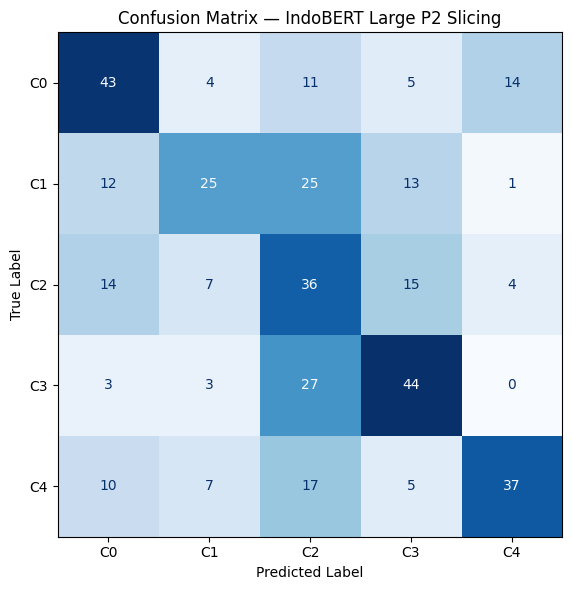

In [64]:
# ============================================================
# CELL 22 — CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=[0, 1, 2, 3, 4]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=EXPECTED_LABELS
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Confusion Matrix — IndoBERT Large P2 Slicing"
)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

Available history columns:
['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_accuracy', 'eval_precision', 'eval_recall', 'eval_macro_f1', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


,epoch,loss,eval_loss,eval_accuracy,eval_macro_f1,learning_rate
0,1.0,1.4353,NaN,NaN,NaN,0.0
1,1.0,NaN,1.2863,0.4458,0.4222,NaN
2,2.0,1.0080,NaN,NaN,NaN,0.0
3,2.0,NaN,1.3008,0.5074,0.4886,NaN
4,3.0,0.5174,NaN,NaN,NaN,0.0
5,3.0,NaN,2.2188,0.5099,0.5088,NaN
6,4.0,0.2018,NaN,NaN,NaN,0.0
7,4.0,NaN,2.7642,0.5197,0.5230,NaN
8,5.0,0.0934,NaN,NaN,NaN,0.0
9,5.0,NaN,3.6444,0.4852,0.4851,NaN


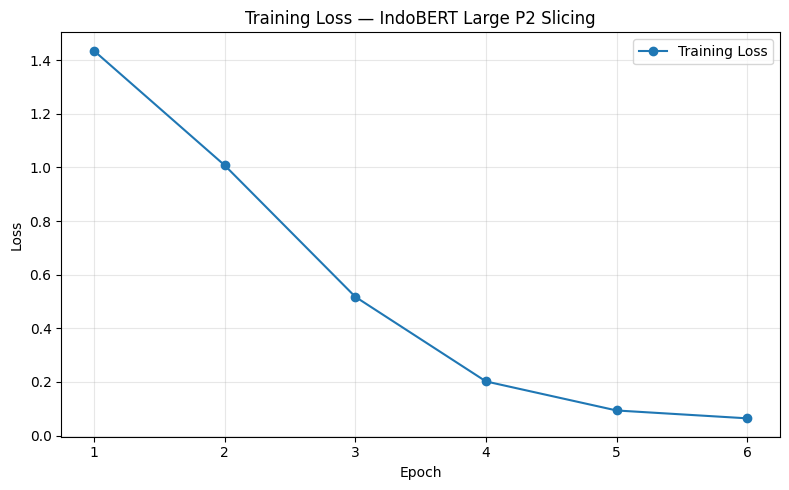

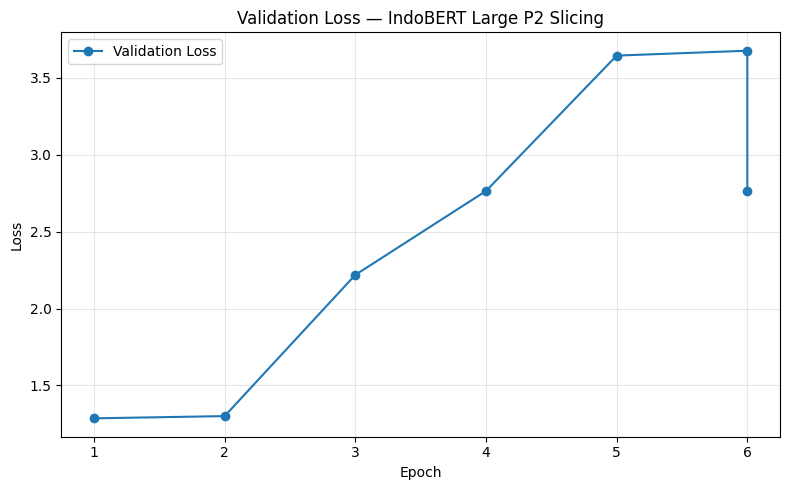

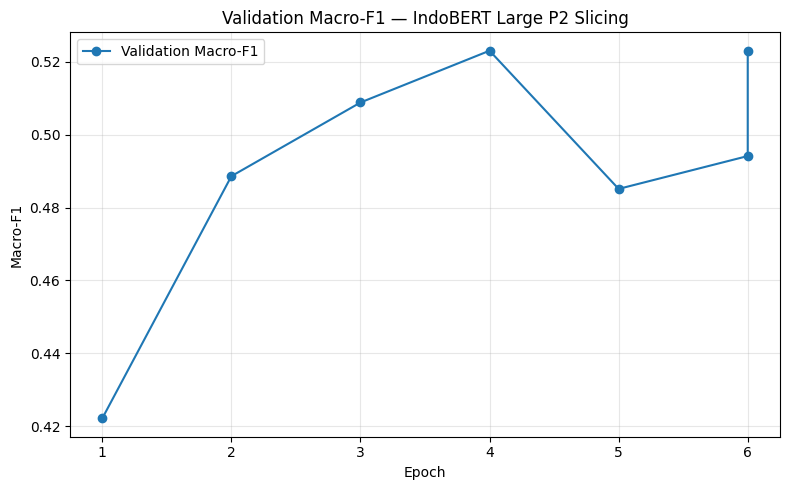

In [65]:
# ============================================================
# CELL 23 — TRAINING HISTORY & LOSS CURVES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Extract training history
history = pd.DataFrame(trainer.state.log_history)

print("Available history columns:")
print(history.columns.tolist())

# Display relevant history
history_columns = [
    col for col in [
        "epoch",
        "loss",
        "eval_loss",
        "eval_accuracy",
        "eval_macro_f1",
        "learning_rate"
    ]
    if col in history.columns
]

display(
    history[history_columns].round(4)
)

# ============================================================
# 1. TRAINING LOSS
# ============================================================

train_history = history.dropna(
    subset=["loss"]
)

plt.figure(figsize=(8, 5))

plt.plot(
    train_history["epoch"],
    train_history["loss"],
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss — IndoBERT Large P2 Slicing")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 2. VALIDATION LOSS
# ============================================================

val_loss_history = history.dropna(
    subset=["eval_loss"]
)

plt.figure(figsize=(8, 5))

plt.plot(
    val_loss_history["epoch"],
    val_loss_history["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss — IndoBERT Large P2 Slicing")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3. VALIDATION MACRO-F1
# ============================================================

val_f1_history = history.dropna(
    subset=["eval_macro_f1"]
)

plt.figure(figsize=(8, 5))

plt.plot(
    val_f1_history["epoch"],
    val_f1_history["eval_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Validation Macro-F1 — IndoBERT Large P2 Slicing")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Train slice count statistics:
count    3052.000000
mean        1.038008
std         0.303800
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         6.000000
dtype: float64


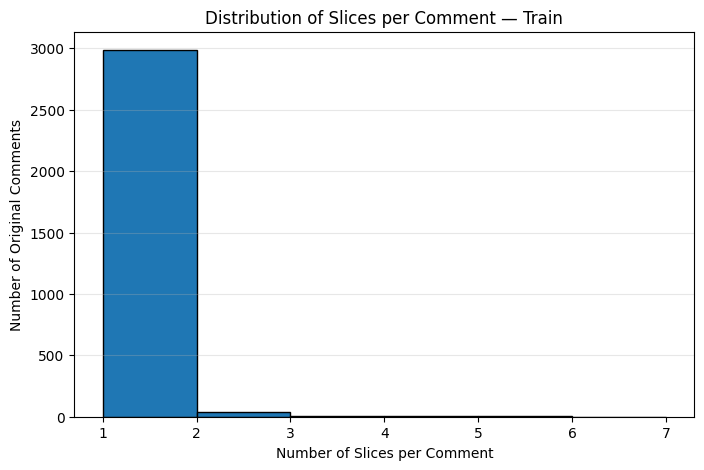

In [66]:
# ============================================================
# CELL 24 — SLICE COUNT ANALYSIS
# ============================================================

slice_count = (
    train_sliced
    .groupby("original_index")
    .size()
)

print("Train slice count statistics:")
print(slice_count.describe())

plt.figure(figsize=(8, 5))

plt.hist(
    slice_count,
    bins=range(1, int(slice_count.max()) + 2),
    edgecolor="black"
)

plt.xlabel("Number of Slices per Comment")
plt.ylabel("Number of Original Comments")
plt.title("Distribution of Slices per Comment — Train")
plt.grid(axis="y", alpha=0.3)

plt.show()

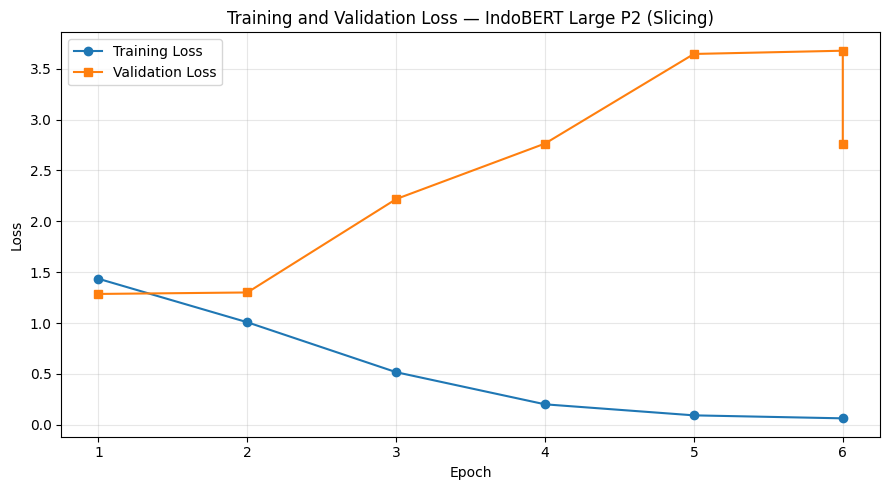

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.DataFrame(trainer.state.log_history)

train_loss = history.dropna(subset=["loss"])
val_loss = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 5))

plt.plot(
    train_loss["epoch"],
    train_loss["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    val_loss["epoch"],
    val_loss["eval_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss — IndoBERT Large P2 (Slicing)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()